In [1]:

import pandas as pd

# Load the Excel dataset
df = pd.read_excel('/content/Online Retail.xlsx')

# Display the first 5 rows
display(df.head())

# Display the dataset size
print("Dataset shape:", df.shape)

# Display column names
print("Column names:")
print(df.columns.tolist())


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Dataset shape: (541909, 8)
Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [2]:
!pip install openpyxl

In [3]:

# Check missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Check data types
print("\nColumn data types:")
print(df.dtypes)


Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Number of duplicate rows:
5268

Column data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [4]:

# Make a copy of the original dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove rows where CustomerID is missing
df_clean = df_clean.dropna(subset=['CustomerID'])

# Remove cancelled transactions
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]

# Keep only positive quantities and prices
df_clean = df_clean[
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice'] > 0)
].copy()

# Convert CustomerID to integer
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

# Calculate total amount for each transaction line
df_clean['TotalAmount'] = (
    df_clean['Quantity'] * df_clean['UnitPrice']
)

# Display the cleaned dataset summary
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Remaining missing values:")
print(df_clean.isnull().sum())
print("\nFirst five cleaned rows:")
display(df_clean.head())


Original rows: 541909
Cleaned rows: 392692
Remaining missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalAmount    0
dtype: int64

First five cleaned rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [5]:

import pandas as pd

# Convert InvoiceDate to datetime
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# Set the analysis date to one day after the last transaction
analysis_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM values for each customer
rfm = df_clean.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (analysis_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalAmount', 'sum')
).reset_index()

# Display the first five customers
display(rfm.head())

# Display the number of customers
print("Total customers:", rfm['CustomerID'].nunique())

# Summary of RFM values
display(rfm[['Recency', 'Frequency', 'Monetary']].describe())


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


Total customers: 4338


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [6]:

# Assign scores from 1 to 5
# Higher Recency score = more recent purchase

rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine the three scores
rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

display(rfm.head(10))
print("RFM scoring completed!")


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,1,77183.60,1,1,5,115
1,12347,2,7,4310.00,5,5,5,555
2,12348,75,4,1797.24,2,4,4,244
3,12349,19,1,1757.55,4,1,4,414
4,12350,310,1,334.40,1,1,2,112
5,12352,36,8,2506.04,3,5,5,355
6,12353,204,1,89.00,1,1,1,111
7,12354,232,1,1079.40,1,1,4,114
8,12355,214,1,459.40,1,1,2,112
9,12356,23,3,2811.43,4,3,5,435


RFM scoring completed!


In [7]:

def assign_segment(row):
    r = row['R_Score']
    f = row['F_Score']

    if r >= 4 and f >= 4:
        return 'Champions'
    elif f >= 4:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'New / Promising'
    elif r <= 2 and f >= 3:
        return 'At-Risk Customers'
    elif r <= 2 and f <= 2:
        return 'Lost / Hibernating'
    elif r >= 3 and f >= 3:
        return 'Potential Loyalists'
    else:
        return 'Regular Customers'

rfm['Customer_Segment'] = rfm.apply(
    assign_segment, axis=1
)

print("Customer segment counts:")
display(
    rfm['Customer_Segment']
    .value_counts()
    .rename_axis('Customer Segment')
    .reset_index(name='Number of Customers')
)

display(rfm.head(10))


Customer segment counts:


,Customer Segment,Number of Customers
0,Champions,1121
1,Lost / Hibernating,1074
2,Loyal Customers,614
3,Potential Loyalists,492
4,At-Risk Customers,376
5,Regular Customers,351
6,New / Promising,310


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,12346,326,1,77183.60,1,1,5,115,Lost / Hibernating
1,12347,2,7,4310.00,5,5,5,555,Champions
2,12348,75,4,1797.24,2,4,4,244,Loyal Customers
3,12349,19,1,1757.55,4,1,4,414,New / Promising
4,12350,310,1,334.40,1,1,2,112,Lost / Hibernating
5,12352,36,8,2506.04,3,5,5,355,Loyal Customers
6,12353,204,1,89.00,1,1,1,111,Lost / Hibernating
7,12354,232,1,1079.40,1,1,4,114,Lost / Hibernating
8,12355,214,1,459.40,1,1,2,112,Lost / Hibernating
9,12356,23,3,2811.43,4,3,5,435,Potential Loyalists


In [8]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import numpy as np

# Prepare RFM features
X = rfm[['Recency', 'Frequency', 'Monetary']].copy()

# Reduce the effect of highly skewed values
X['Frequency'] = np.log1p(X['Frequency'])
X['Monetary'] = np.log1p(X['Monetary'])

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create 4 customer clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")
print("\nCustomers in each cluster:")
display(rfm['Cluster'].value_counts().sort_index())

print("\nAverage RFM values by cluster:")
display(
    rfm.groupby('Cluster')[
        ['Recency', 'Frequency', 'Monetary']
    ].mean().round(2)
)


K-Means clustering completed!

Customers in each cluster:


,count
Cluster,
0,1377
1,938
2,571
3,1452



Average RFM values by cluster:


,Recency,Frequency,Monetary
Cluster,,,
0,58.04,1.51,384.22
1,259.41,1.37,385.39
2,19.77,15.84,9823.43
3,46.06,4.21,1644.26


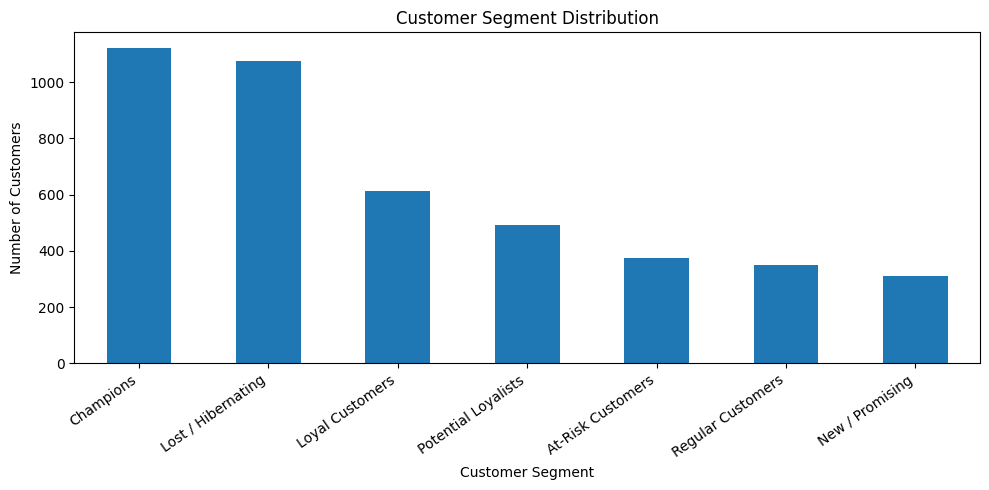

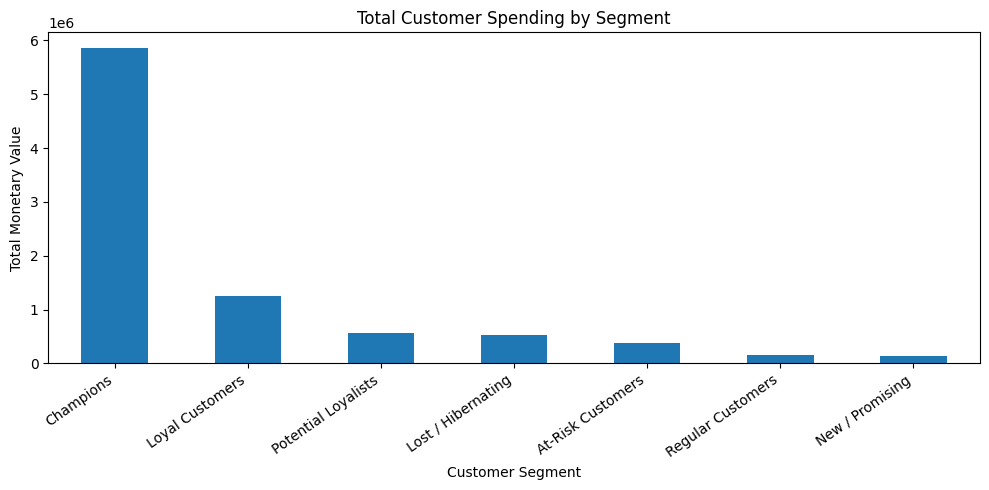

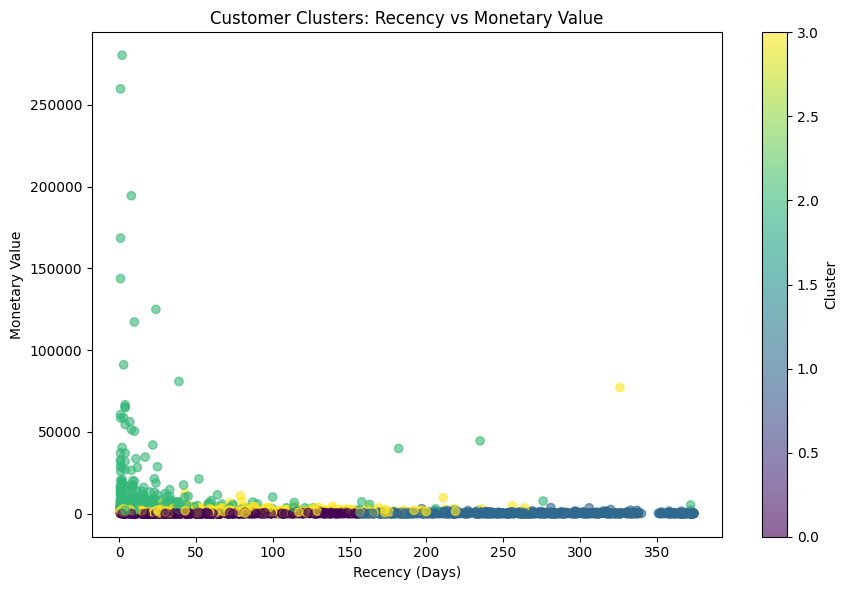

In [9]:

import matplotlib.pyplot as plt

# Chart 1: Customer segment distribution
segment_counts = rfm['Customer_Segment'].value_counts()

segment_counts.plot(
    kind='bar',
    figsize=(10, 5),
    title='Customer Segment Distribution'
)
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

# Chart 2: Total monetary value by segment
segment_sales = rfm.groupby(
    'Customer_Segment'
)['Monetary'].sum().sort_values(ascending=False)

segment_sales.plot(
    kind='bar',
    figsize=(10, 5),
    title='Total Customer Spending by Segment'
)
plt.xlabel('Customer Segment')
plt.ylabel('Total Monetary Value')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

# Chart 3: K-Means cluster visualization
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    rfm['Recency'],
    rfm['Monetary'],
    c=rfm['Cluster'],
    alpha=0.6
)

plt.xlabel('Recency (Days)')
plt.ylabel('Monetary Value')
plt.title('Customer Clusters: Recency vs Monetary Value')
plt.colorbar(scatter, label='Cluster')
plt.tight_layout()
plt.show()


In [10]:

segment_summary = rfm.groupby('Customer_Segment').agg(
    Customers=('CustomerID', 'count'),
    Average_Recency=('Recency', 'mean'),
    Average_Frequency=('Frequency', 'mean'),
    Total_Revenue=('Monetary', 'sum'),
    Average_Spending=('Monetary', 'mean')
).round(2).sort_values(
    'Total_Revenue', ascending=False
)

display(segment_summary)

print("\nSuggested marketing actions:")

actions = {
    'Champions': 'Reward with loyalty benefits and early access.',
    'Loyal Customers': 'Encourage repeat purchases and referrals.',
    'New / Promising': 'Use onboarding offers and product recommendations.',
    'Potential Loyalists': 'Use personalized offers to build loyalty.',
    'At-Risk Customers': 'Send win-back campaigns and relevant offers.',
    'Lost / Hibernating': 'Test reactivation campaigns with limited incentives.',
    'Regular Customers': 'Use relevant recommendations to increase engagement.'
}

for segment in segment_summary.index:
    print(f"{segment}: {actions.get(segment, 'Review customer behavior and test a targeted campaign.')}")


,Customers,Average_Recency,Average_Frequency,Total_Revenue,Average_Spending
Customer_Segment,,,,,
Champions,1121,13.00,10.05,5857798.93,5225.51
Loyal Customers,614,88.81,5.34,1261132.64,2053.96
Potential Loyalists,492,29.31,2.33,573070.58,1164.78
Lost / Hibernating,1074,216.68,1.10,523803.28,487.71
At-Risk Customers,376,162.66,2.30,370556.74,985.52
Regular Customers,351,52.50,1.16,158607.28,451.87
New / Promising,310,18.10,1.25,142239.44,458.84



Suggested marketing actions:
Champions: Reward with loyalty benefits and early access.
Loyal Customers: Encourage repeat purchases and referrals.
Potential Loyalists: Use personalized offers to build loyalty.
Lost / Hibernating: Test reactivation campaigns with limited incentives.
At-Risk Customers: Send win-back campaigns and relevant offers.
Regular Customers: Use relevant recommendations to increase engagement.
New / Promising: Use onboarding offers and product recommendations.


In [11]:

output_file = '/content/RFM_Customer_Segmentation_Results.xlsx'

with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    df_clean.to_excel(
        writer, sheet_name='Cleaned Transactions', index=False
    )
    rfm.to_excel(
        writer, sheet_name='Customer RFM', index=False
    )
    segment_summary.to_excel(
        writer, sheet_name='Segment Summary'
    )

print("Export completed:", output_file)

from google.colab import files
files.download(output_file)


Export completed: /content/RFM_Customer_Segmentation_Results.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

# Verify the final RFM analysis results

print("1. Cleaned transaction rows:", len(df_clean))
print("2. Total customers:", rfm['CustomerID'].nunique())
print("3. Customer segments:")
print(rfm['Customer_Segment'].value_counts())

print("\n4. K-Means clusters:")
print(rfm['Cluster'].value_counts().sort_index())

print("\n5. Missing values in RFM results:")
print(rfm.isnull().sum())

print("\n6. Final RFM sample:")
display(rfm.head(10))


1. Cleaned transaction rows: 392692
2. Total customers: 4338
3. Customer segments:
Customer_Segment
Champions              1121
Lost / Hibernating     1074
Loyal Customers         614
Potential Loyalists     492
At-Risk Customers       376
Regular Customers       351
New / Promising         310
Name: count, dtype: int64

4. K-Means clusters:
Cluster
0    1377
1     938
2     571
3    1452
Name: count, dtype: int64

5. Missing values in RFM results:
CustomerID          0
Recency             0
Frequency           0
Monetary            0
R_Score             0
F_Score             0
M_Score             0
RFM_Score           0
Customer_Segment    0
Cluster             0
dtype: int64

6. Final RFM sample:


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment,Cluster
0,12346,326,1,77183.60,1,1,5,115,Lost / Hibernating,3
1,12347,2,7,4310.00,5,5,5,555,Champions,2
2,12348,75,4,1797.24,2,4,4,244,Loyal Customers,3
3,12349,19,1,1757.55,4,1,4,414,New / Promising,3
4,12350,310,1,334.40,1,1,2,112,Lost / Hibernating,1
5,12352,36,8,2506.04,3,5,5,355,Loyal Customers,2
6,12353,204,1,89.00,1,1,1,111,Lost / Hibernating,1
7,12354,232,1,1079.40,1,1,4,114,Lost / Hibernating,1
8,12355,214,1,459.40,1,1,2,112,Lost / Hibernating,1
9,12356,23,3,2811.43,4,3,5,435,Potential Loyalists,3
